# WEEK 3

# Project Title    : Data-Driven Inventory Management And Demand Forecasting
# Approach        : Exploratory Data Analysis, Statistical Analysis, Data  
#                    Visualization, and Logistics Performance Analysis
# Technology     : Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn
# Report Type   : Advanced Data Analysis and Visualization in Logistics


# BY:
#   V.THANIGAI MURUGAN
#   B.TECH CSE


# A. Loading libraries:

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

# B. Exploratory Data Analysis (EDA):

In [ ]:
np.random.seed(42)
n = 500
df = pd.DataFrame({"shipment_id": [f"S{i:04d}" for i in range(n)],
    "distance_km": np.random.gamma(2.5, 90, n).clip(10, 900),
    "weight_kg": np.random.lognormal(4.2, .65, n).clip(2, 1500),
    "order_units": np.random.poisson(35, n).clip(1, 120),
    "traffic_index": np.random.uniform(.1, 1, n),
    "weather_risk": np.random.uniform(0, 1, n),
    "warehouse_hours": np.random.gamma(2, 1.2, n).clip(.2, 12)})
df["delivery_hours"] = (3 + .035*df.distance_km + 4.5*df.traffic_index+ 3.2*df.weather_risk
                                       + .55*df.warehouse_hours+ np.random.normal(0, 4, n)).clip(2, None)
df["transport_cost_inr"] = (120 + 5.2*df.distance_km + .75*df.weight_kg+ 18*df.traffic_index
                                            + np.random.normal(0, 180, n)).clip(100, None)

# C. Demonstrate missing-value checks and cleaning:

In [ ]:
for col in ["traffic_index", "weight_kg"]:
            df.loc[np.random.choice(df.index, 8, replace=False), col] = np.nan
print("Shape:", df.shape)
print("Missing values before cleaning:\\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df.describe().round(2))
num = df.select_dtypes(include="number").columns
df[num] = df[num].fillna(df[num].median())
df = df.drop_duplicates()
print(df[["distance_km","weight_kg","delivery_hours","transport_cost_inr"]]
      .agg(["mean","median","std","min","max"]).round(2))
corr = df.select_dtypes(include="number").corr()
print("Correlation with delivery time:\\n", corr["delivery_hours"].sort_values(ascending=False).round(3))

Shape: (500, 9)
Missing values before cleaning:\n shipment_id           0
distance_km           0
weight_kg             8
order_units           0
traffic_index         8
weather_risk          0
warehouse_hours       0
delivery_hours        0
transport_cost_inr    0
dtype: int64
Duplicate rows: 0
       distance_km  weight_kg  order_units  traffic_index  weather_risk  \
count       500.00     492.00       500.00         492.00        500.00   
mean        223.45      81.13        34.98           0.55          0.49   
std         135.07      57.29         6.17           0.26          0.29   
min          10.00       6.94        15.00           0.10          0.00   
25%         125.25      42.82        31.00           0.32          0.23   
50%         197.09      67.23        35.00           0.56          0.47   
75%         289.82      97.65        39.00           0.75          0.75   
max         773.17     458.18        56.00           1.00          1.00   

       warehouse_hours  del

# D. Data Visualization:

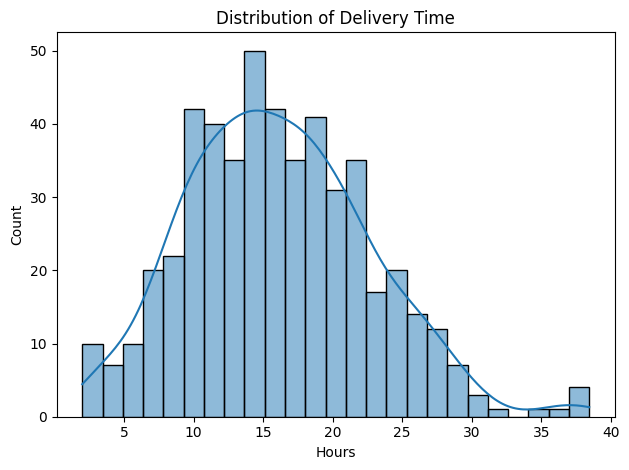

In [ ]:
sns.histplot(df["delivery_hours"], bins=25, kde=True)
plt.title("Distribution of Delivery Time"); plt.xlabel("Hours"); plt.tight_layout(); plt.show()

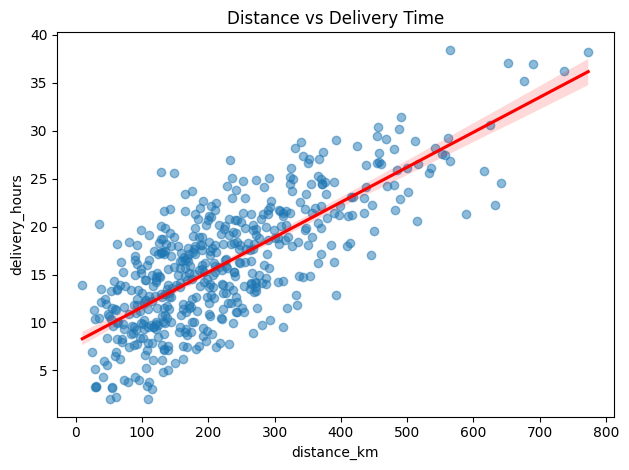

In [ ]:
sns.regplot(data=df, x="distance_km", y="delivery_hours",scatter_kws={"alpha":.5}, line_kws={"color":"red"})
plt.title("Distance vs Delivery Time"); plt.tight_layout(); plt.show()

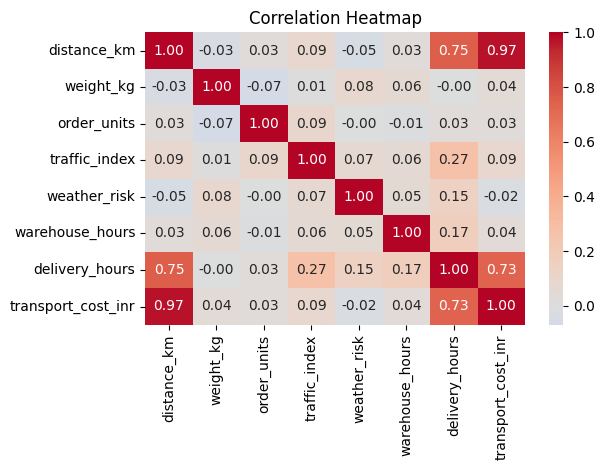

In [ ]:
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()